# ① 球種・球速・投球位置と空振り確率

## 研究目的と仮説

球種、球速、実際の投球位置、カウント、投打の左右と空振り確率の関係を検討する。球速だけでは説明できない非線形性や条件間の交互作用があり、特徴量の追加によって予測性能が改善するという仮説を設定した。

## 使用データと対象定義

MLB Statcastの2025年4〜5月のレギュラーシーズン投球を使用する。バントを除くスイングを対象とし、`swinging_strike`、`swinging_strike_blocked`、`swinging_pitchout`を空振りと定義する。`foul`、`foul_tip`、`hit_into_play`、`foul_pitchout`は接触したスイングに含め、見逃しは分母から除外する。

実際の投球位置を使うため、投球後の条件付き結果推定として位置付ける。投球前の予測精度や球種変更の因果効果を評価する分析ではない。

In [1]:
# リポジトリ内の共通処理を読み込む
from pathlib import Path
import sys
sys.path.insert(0, str(Path.cwd() / 'src'))
from mlb_portfolio.data import *
from mlb_portfolio.analysis import *

# 集計表の表示範囲を設定する（分析対象の行数・列数は変更しない）
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_rows', 35)


## 1. データ品質と対象選択

取得済みデータを読み込み、選択条件による件数変化、要約統計、欠損率と評価期間を確認する。取得ログ・データ定義は[出典と利用条件](../DATA_SOURCES.md)を参照。

In [2]:
# 取得済みキャッシュを優先して投球データを読み込む
raw = statcast_data()
# バントを除くスイングを選び、空振りラベルと位置の特徴量を作成する
df = swings(raw)
# 対象選択の件数、要約統計、欠損率、時間分割ごとの陽性率を確認する
quality(raw, df, 'whiff')

game_type
R    234985
Name: pitches, dtype: int64

Pitch keys duplicated: 0


,rows,stage
0,234985,deduplicated_source
1,234985,regular_season
2,110368,non_bunt_swings
3,110368,eligible


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
pitch_type,110367,16,FF,35594,NaN,NaN,NaN,NaN,NaN,NaN,NaN
game_date,110368,61,2025-05-14,2420,NaN,NaN,NaN,NaN,NaN,NaN,NaN
release_speed,110367.0,<NA>,<NA>,<NA>,89.401182,5.97429,34.3,85.3,90.1,94.2,103.8
release_pos_x,110367.0,<NA>,<NA>,<NA>,-0.873044,1.896279,-5.14,-2.22,-1.6,0.43,4.55
release_pos_z,110367.0,<NA>,<NA>,<NA>,5.75681,0.508928,1.13,5.49,5.82,6.07,7.47
player_name,110368,641,"Crochet, Garrett",550,NaN,NaN,NaN,NaN,NaN,NaN,NaN
batter,110368.0,<NA>,<NA>,<NA>,652304.16898,49720.335934,455117.0,641857.0,666158.0,678882.0,810938.0
pitcher,110368.0,<NA>,<NA>,<NA>,647151.037746,51556.219984,434378.0,621237.0,663893.0,676969.0,820862.0
events,51394,19,field_out,24594,NaN,NaN,NaN,NaN,NaN,NaN,NaN
description,110368,5,foul,41533,NaN,NaN,NaN,NaN,NaN,NaN,NaN


description
foul                       41533
hit_into_play              41310
swinging_strike            23884
foul_tip                    2343
swinging_strike_blocked     1298
Name: count, dtype: int64

,split,n,positive_rate,start,end
0,train,53691,0.232236,2025-04-01,2025-04-30
1,validation,26906,0.224560,2025-05-01,2025-05-15
2,test,29771,0.224077,2025-05-16,2025-05-31


## 2. 探索的分析と統計的検討

分布・集計・可視化から傾向を確認し、訓練データのみで統計モデルを推定する。係数と区間は探索的な関連として解釈する。

,size,sum,mean,lower95,upper95
pitch_type,,,,,
CH,11956,3460,0.289394,0.281335,0.297590
CS,59,13,0.220339,0.133542,0.341327
CU,5778,1697,0.293700,0.282097,0.305578
EP,125,1,0.008000,0.001414,0.043925
FA,127,9,0.070866,0.037728,0.129203
FC,8647,1747,0.202035,0.193706,0.210630
FF,35594,6481,0.182081,0.178107,0.186125
FO,225,83,0.368889,0.308536,0.433643
FS,4366,1369,0.313559,0.299967,0.327480


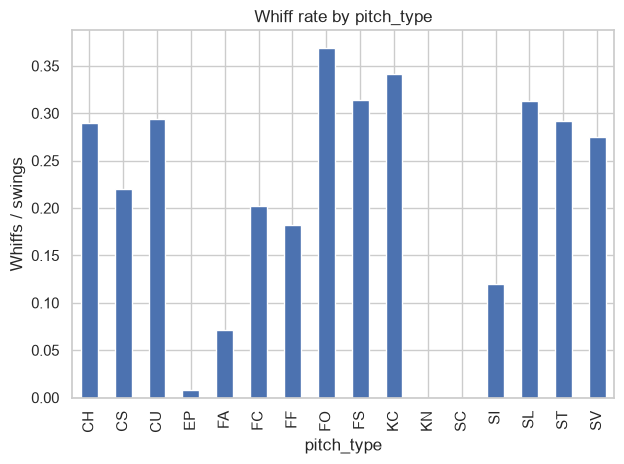

,size,sum,mean,lower95,upper95
speed_band,,,,,
"(0, 80]",7309,2023,0.276782,0.266644,0.287154
"(80, 85]",19127,5572,0.291316,0.284919,0.297797
"(85, 90]",28574,7922,0.277245,0.272085,0.282465
"(90, 95]",35196,5928,0.168428,0.164555,0.172374
"(95, 100]",19662,3604,0.183298,0.177952,0.188768
"(100, 110]",499,132,0.264529,0.227734,0.304922


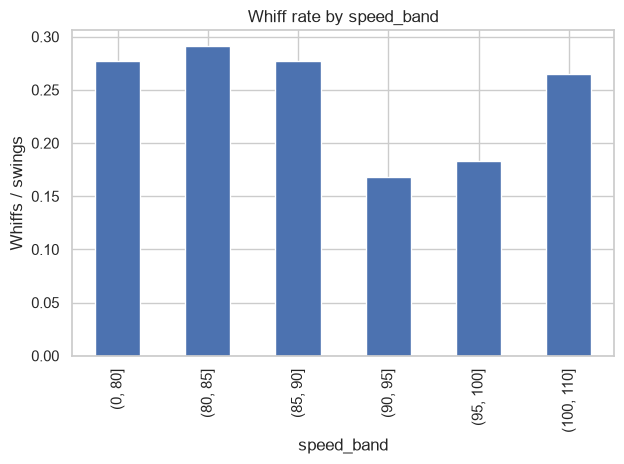

,size,sum,mean,lower95,upper95
handedness,,,,,
L vs L,8396,2098,0.249881,0.240736,0.259255
L vs R,20053,4578,0.228295,0.222538,0.234156
R vs L,39874,8642,0.216733,0.212716,0.220804
R vs R,42045,9864,0.234606,0.230580,0.238680


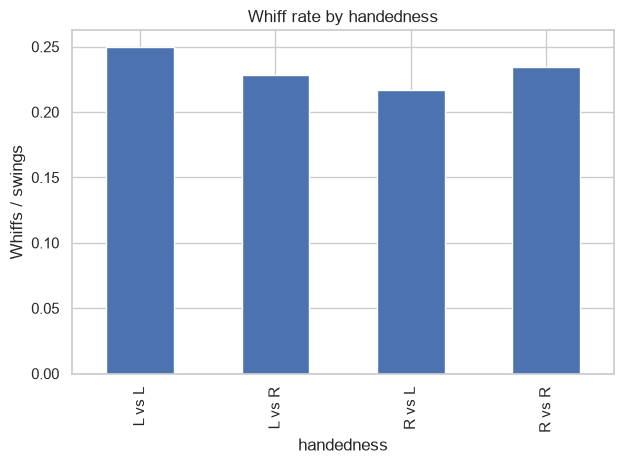

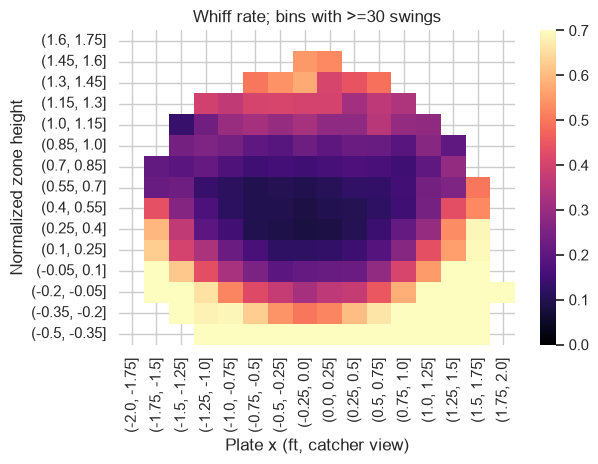

,coefficient,lower95,upper95,p_value
Intercept,-0.397600,-1.269759,0.474559,3.715848e-01
C(pitch_type)[T.CU],-0.196684,-0.341437,-0.051932,7.741773e-03
C(pitch_type)[T.FC],-0.314766,-0.432054,-0.197477,1.441096e-07
C(pitch_type)[T.FF],-0.474285,-0.595121,-0.353449,1.438096e-14
C(pitch_type)[T.FO],-0.014364,-0.399062,0.370334,9.416596e-01
C(pitch_type)[T.FS],0.074234,-0.058691,0.207159,2.737039e-01
C(pitch_type)[T.KC],-0.044808,-0.245575,0.155959,6.617986e-01
C(pitch_type)[T.SI],-0.976742,-1.106301,-0.847182,2.089732e-49
C(pitch_type)[T.SL],0.049147,-0.041459,0.139752,2.877205e-01
C(pitch_type)[T.ST],0.080269,-0.033862,0.194400,1.680617e-01


Training-only exploratory associations; game-cluster robust SE; no causal interpretation or multiple-testing correction.


In [3]:
# 球種・球速帯・左右別の率と投球位置のヒートマップを出力する
whiff_eda(df)
# 訓練データのみで交互作用を含む統計モデルを推定する
inference(df, 'whiff')

## 3. モデル比較と評価方法

2025年4月を訓練、5月1〜15日を検証、5月16〜31日を固定テストとする。定数確率、基本・特徴量追加ロジスティック回帰、設定の異なるRandom Forestを比較し、検証log lossで選択する。

基本特徴は球速・横位置・正規化した高さ・カウント・球種・投打左右とし、球速×高さ・回転数・変化量を追加する。欠損補完・標準化・カテゴリ符号化はPipeline内で訓練データから学習する。乱数は42に固定する。

固定テストでは選択モデルと定数確率を評価する。ROC-AUC、average precision、log loss、Brier score、閾値0.5のAccuracyを記録する。試合単位の対応付きブートストラップ400回でlog loss差の95%区間を算出する。

,task,model,split,n_train,n_eval,features,ROC_AUC,PR_AUC_AP,log_loss,Brier,accuracy_0.5
0,whiff,baseline_mean,validation,53691,26906,"release_speed,plate_x,z_norm,balls,strikes,pit...",0.500000,0.224560,0.532785,0.174192,0.775440
1,whiff,logistic_basic,validation,53691,26906,"release_speed,plate_x,z_norm,balls,strikes,pit...",0.645825,0.478871,0.504989,0.160855,0.787334
2,whiff,logistic_extended,validation,53691,26906,"release_speed,plate_x,z_norm,balls,strikes,spe...",0.689879,0.476843,0.484262,0.153617,0.797220
3,whiff,rf_leaf20,validation,53691,26906,"release_speed,plate_x,z_norm,balls,strikes,spe...",0.769748,0.573999,0.436854,0.137000,0.817996
4,whiff,rf_leaf50,validation,53691,26906,"release_speed,plate_x,z_norm,balls,strikes,spe...",0.766280,0.567896,0.441415,0.138516,0.815320
5,whiff,rf_leaf20,test,53691,29771,NaN,0.767755,0.559666,0.440702,0.138815,0.813711
6,whiff,baseline_mean,test,53691,29771,NaN,0.500000,0.224077,0.532208,0.173933,0.775923


Validation-selected: rf_leaf20


,comparison,metric,lower95,upper95,clusters,bootstrap
0,rf_leaf20 minus baseline_mean,log_loss,-0.095844,-0.086468,215,400


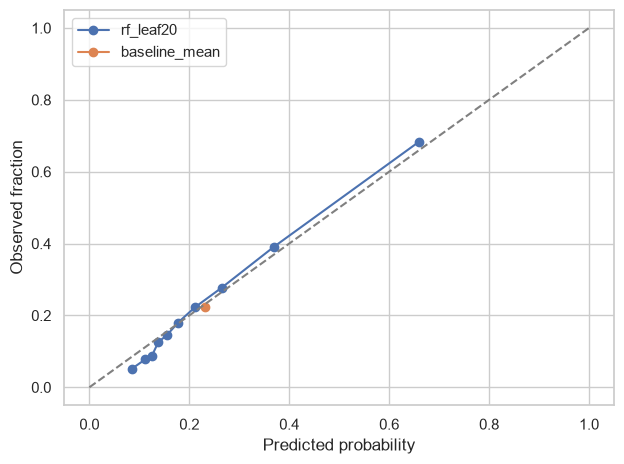

In [4]:
# 検証データでモデルを固定し、テスト指標・図・実験CSVを出力する
results = evaluate(df, 'whiff')

## 4. 結果の解釈と限界

基本ロジスティック回帰に球速×高さ・回転・変化量を追加すると、検証log lossは0.505から0.484へ改善した。検証で選択したRandom Forest（最小葉20）のテストlog lossは0.441、定数確率は0.532、ROC-AUCは0.768だった。

球種別ではスライダー31.3%、フォーシーム18.2%、シンカー11.9%の空振り率だった。位置図では中央付近より端・ゾーン外で高い傾向があるが、対象はスイングされた球に限られる。見逃しや四球を含まないため、最適な配球や球種変更の因果効果には直接結び付けられない。

率のWilson区間は独立試行近似による記述用の区間である。統計モデルでは試合内の依存を考慮するが、未観測交絡や多重比較は残る。別年度・未知選手への外部検証は未実施。詳細は[分析レポート](../reports/REPORT.md)に記載する。